# Breast Cancer Winsconsin (Diagnostic)
Classify a tumor as malignant or benign based on the features in the dataset

In [1]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## Data Loading

In [2]:
# fetch dataset 
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17) 

X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# M = 1, B = 0
y = y["Diagnosis"].map({"B": 0, "M": 1}).to_frame()

In [3]:
# features
X.head()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
# targets
y.head()

,Diagnosis
0,1
1,1
2,1
3,1
4,1


## Splitting into Training Data and Test Data

In [5]:
X_training, X_test, y_training, y_test = train_test_split(X, y, test_size=0.25)

In [6]:
X_training.shape, y_training.shape

((426, 30), (426, 1))

In [7]:
 X_test.shape, y_test.shape

((143, 30), (143, 1))

### Features Normalize

In [8]:
scaler = StandardScaler()
X_training = scaler.fit_transform(X_training)
X_test = scaler.transform(X_test)

## Neural Network Structure

We choose 16 neurons for hidden layer because the input layer has 30 neurons and the output layer has 1 neuron ( binary classification ). So, (30 + 1)/2 = 15.5 which approximated for 16.

Since this is a binary classification problem, we use the sigmoid activation function for the output layer.

In [9]:
neural_network = Sequential([
    tf.keras.Input(shape=(30,)),
    tf.keras.layers.Dense(units=16, activation='relu', kernel_initializer='random_uniform'),
    tf.keras.layers.Dense(units=1, activation='sigmoid')
])

neural_network.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

- 30 neurons in the input layer * 16 neurons in the hidden layer = 480 neurons 

    496 params - 480 = 16, which is the bias introduction in the hidden layer

- 17 params = 16 neurons in hidden layer connected in a only neuron of output + a bias

### Representation

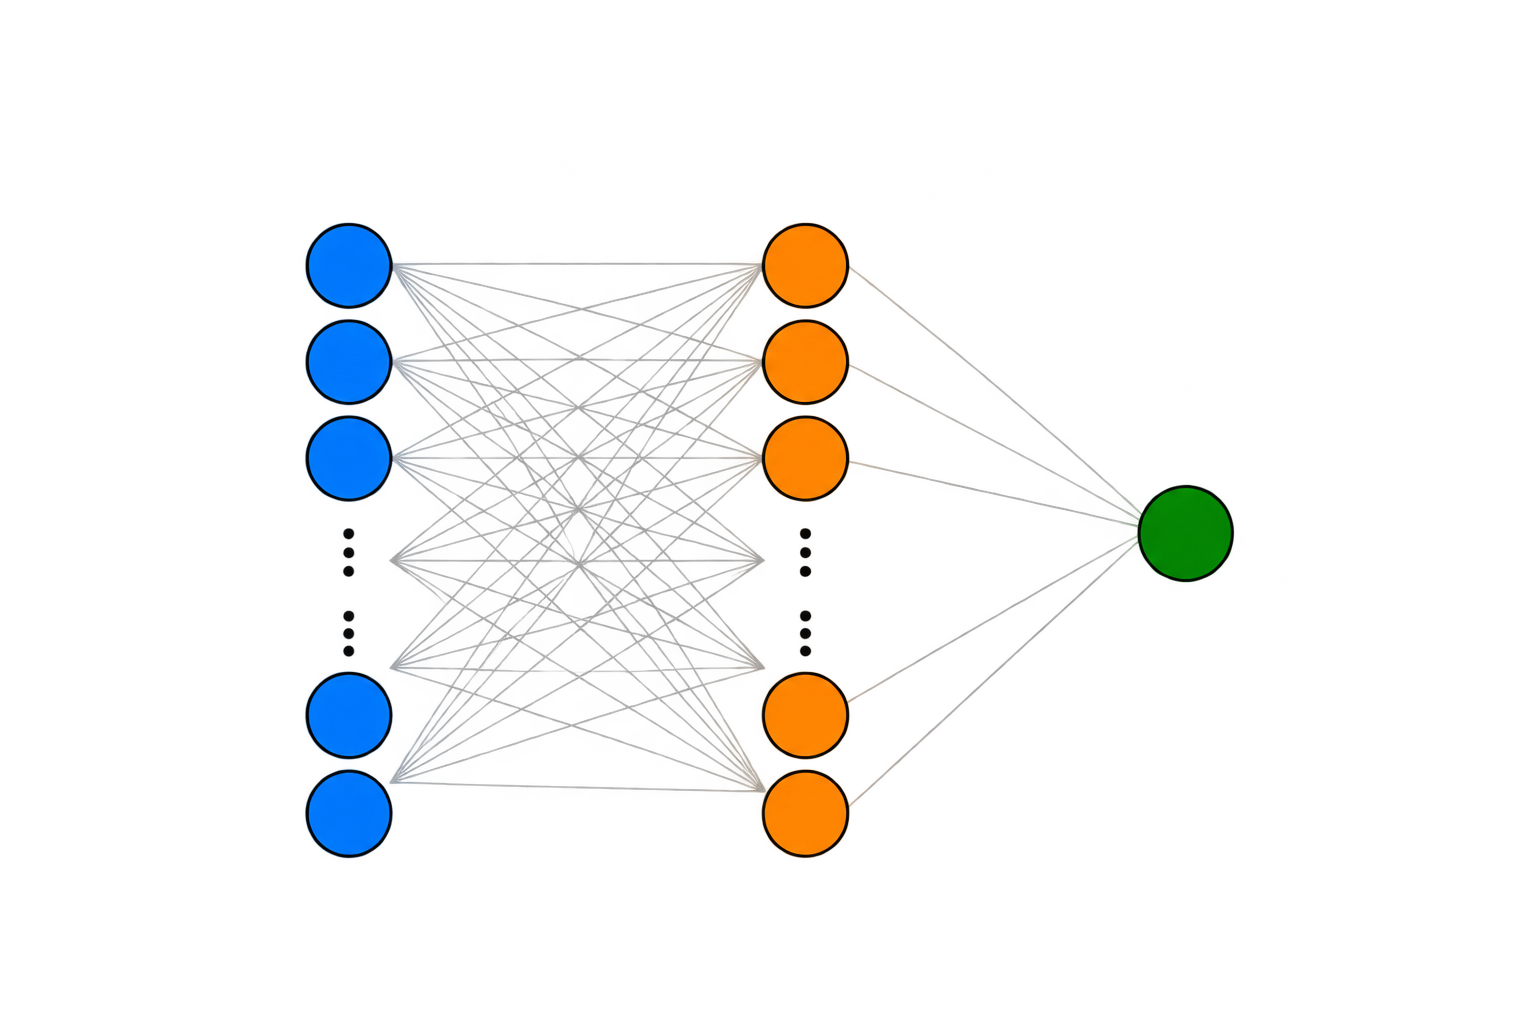

### Params Configuration

In [10]:
neural_network.compile(optimizer="adam", loss="binary_crossentropy", metrics=["binary_accuracy"])

In [11]:
neural_network.fit(X_training, y_training, batch_size=10, epochs=100)

Epoch 1/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - binary_accuracy: 0.8662 - loss: 0.5483  
Epoch 2/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9437 - loss: 0.3090
Epoch 3/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9484 - loss: 0.2000
Epoch 4/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9624 - loss: 0.1485
Epoch 5/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9718 - loss: 0.1197
Epoch 6/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9742 - loss: 0.1024 
Epoch 7/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9742 - loss: 0.0903
Epoch 8/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9812 - loss: 0.0819
Epoch 9/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9836 - loss: 0.0751
Epoch 10/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9836 - loss: 0.0704
Epoch 11/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.983

The accuracy values ​​above are being calculated for the training set itself, which is not ideal. To do this correctly, we will use the test set.

In [12]:
predicteds = neural_network.predict(X_test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


In [13]:
predicteds

array([[1.00000000e+00],
       [9.38854992e-01],
       [1.00000000e+00],
       [5.07304867e-06],
       [1.00000000e+00],
       [1.00000000e+00],
       [9.99990761e-01],
       [3.21911066e-05],
       [2.86618569e-08],
       [9.74476516e-01],
       [5.03270794e-03],
       [9.34936013e-03],
       [1.00000000e+00],
       [1.21512040e-02],
       [1.00000000e+00],
       [1.29289811e-05],
       [1.08739994e-06],
       [1.00000000e+00],
       [2.03895937e-07],
       [9.08710063e-01],
       [5.49762866e-08],
       [9.97734964e-01],
       [1.00000000e+00],
       [3.14494173e-06],
       [8.39450222e-04],
       [2.12697705e-05],
       [1.00000000e+00],
       [9.99967396e-01],
       [4.42912054e-08],
       [7.33338165e-05],
       [2.14258898e-06],
       [3.47651425e-04],
       [1.53051615e-02],
       [5.19876368e-03],
       [1.38031281e-10],
       [5.58837280e-02],
       [1.77304377e-03],
       [1.00000000e+00],
       [2.43149640e-04],
       [1.33980671e-02],


In [14]:
predicteds = (neural_network.predict(X_test) > 0.5).astype(int)
predicteds

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


array([[1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
    

In [15]:
accuracy_score(y_test, predicteds)

0.9790209790209791

In [16]:
_confusion_matrix = confusion_matrix(y_test, predicteds)

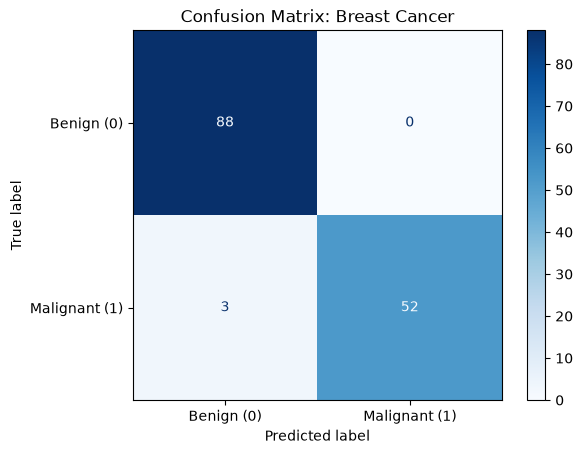

In [18]:
disp = ConfusionMatrixDisplay(confusion_matrix=_confusion_matrix, display_labels=["Benign (0)", "Malignant (1)"])
disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix: Breast Cancer")
plt.show()

## Modifying the Network

In [19]:
new_neural_network = Sequential([
    tf.keras.Input(shape=(30,)),
    tf.keras.layers.Dense(units=16, activation='relu', kernel_initializer='random_uniform'),
    tf.keras.layers.Dense(units=16, activation='relu', kernel_initializer='random_uniform'), # adding another hidden layer
    tf.keras.layers.Dense(units=1, activation='sigmoid')
])

new_neural_network.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 785 (3.07 KB)

 Trainable params: 785 (3.07 KB)

 Non-trainable params: 0 (0.00 B)

### Representation
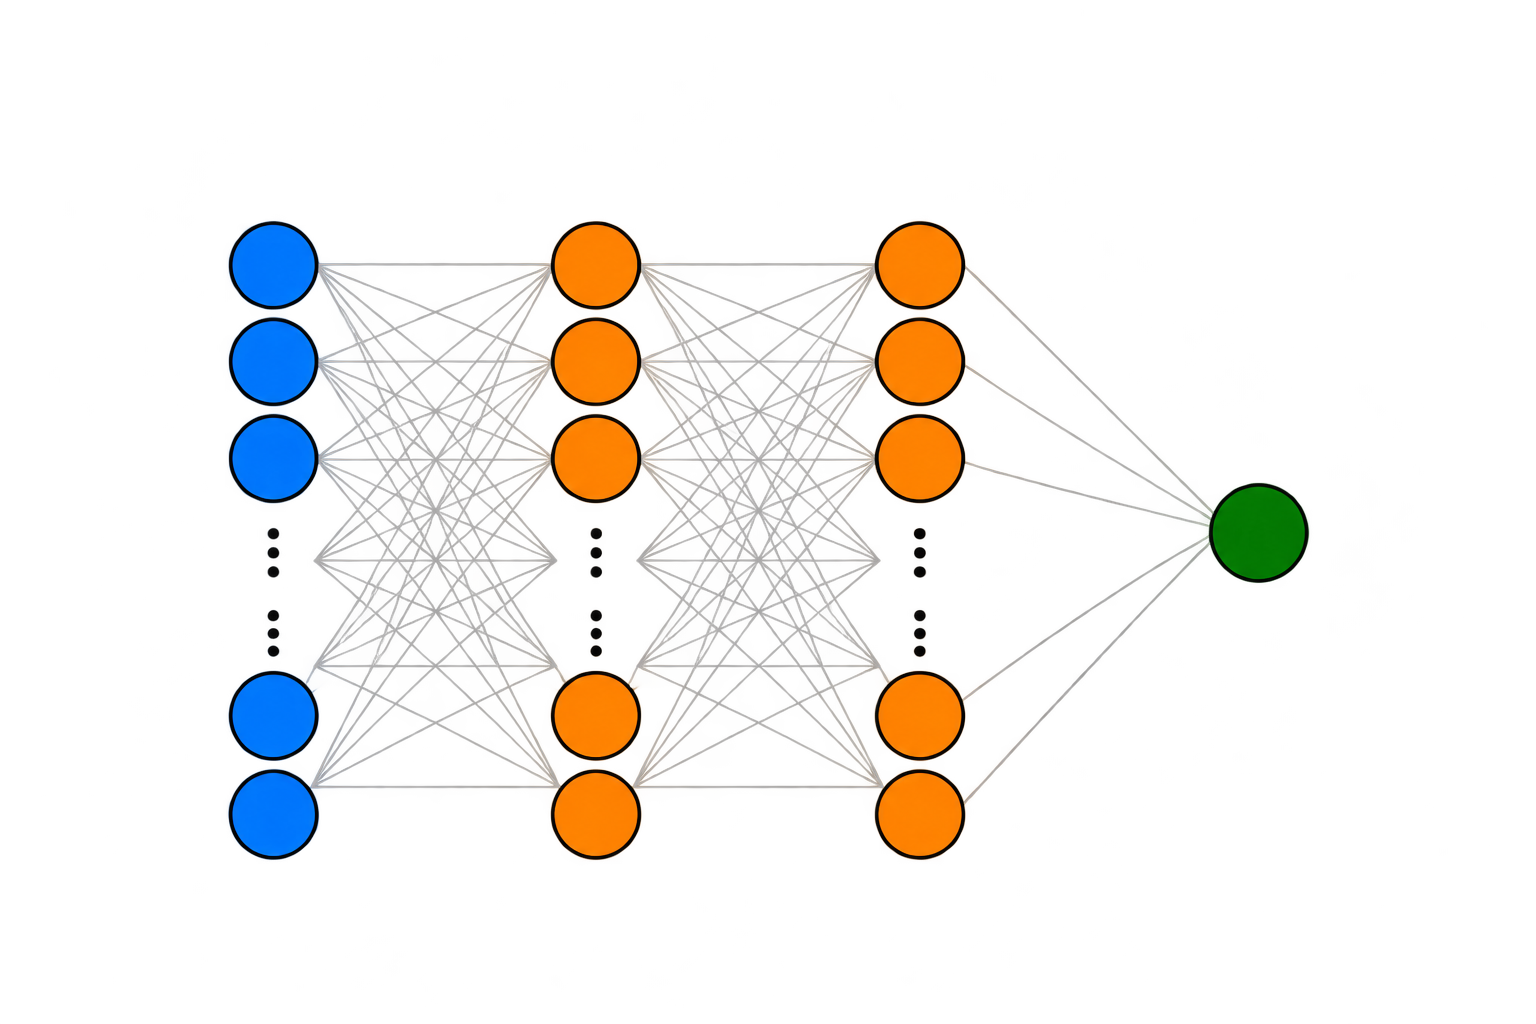

In [20]:
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, clipvalue = 0.5) # clipvalue is a limit for the weights

In [21]:
new_neural_network.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=["binary_accuracy"])

In [22]:
new_neural_network.fit(X_training, y_training, batch_size=10, epochs=100)

Epoch 1/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - binary_accuracy: 0.9155 - loss: 0.6182  
Epoch 2/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9484 - loss: 0.3149
Epoch 3/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9601 - loss: 0.1443
Epoch 4/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9718 - loss: 0.0989
Epoch 5/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9742 - loss: 0.0796
Epoch 6/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9836 - loss: 0.0694
Epoch 7/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - binary_accuracy: 0.9836 - loss: 0.0625
Epoch 8/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9859 - loss: 0.0574
Epoch 9/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9859 - loss: 0.0530
Epoch 10/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - binary_accuracy: 0.9836 - loss: 0.0505 
Epoch 11/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.985

In [23]:
new_predicteds = new_neural_network.predict(X_test)
new_predicteds

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


array([[1.00000000e+00],
       [9.97141600e-01],
       [1.00000000e+00],
       [1.72634303e-11],
       [1.00000000e+00],
       [1.00000000e+00],
       [9.99999940e-01],
       [6.71879476e-08],
       [9.94230418e-15],
       [9.99875665e-01],
       [6.92437461e-05],
       [1.61462653e-04],
       [1.00000000e+00],
       [6.08057519e-07],
       [1.00000000e+00],
       [2.80708651e-10],
       [1.02689923e-09],
       [1.00000000e+00],
       [2.50589724e-13],
       [9.69285548e-01],
       [3.46340957e-13],
       [9.99990463e-01],
       [1.00000000e+00],
       [7.22079549e-11],
       [3.10396831e-06],
       [3.43758327e-10],
       [1.00000000e+00],
       [1.00000000e+00],
       [1.93880399e-15],
       [1.67577401e-08],
       [1.58984298e-10],
       [1.44986529e-07],
       [2.20495946e-04],
       [1.04301968e-07],
       [5.82389679e-17],
       [5.22565544e-02],
       [1.70803341e-05],
       [1.00000000e+00],
       [2.53856758e-09],
       [1.54416528e-04],


In [24]:
new_predicteds = (new_neural_network.predict(X_test) > 0.5).astype(int)
new_predicteds

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


array([[1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [1],
       [1],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
    

In [25]:
accuracy_score(y_test, new_predicteds)

0.986013986013986

In [26]:
new_confusion_matrix = confusion_matrix(y_test, new_predicteds)

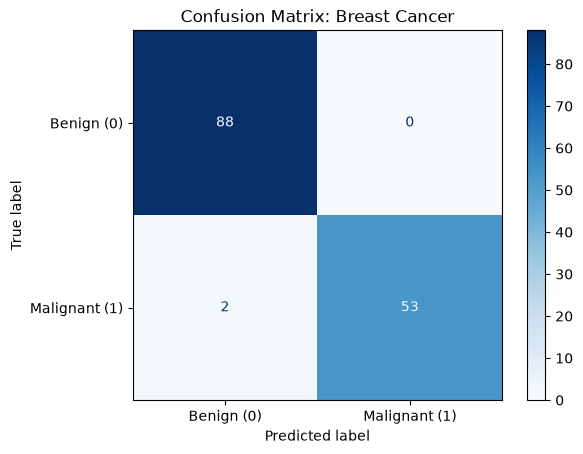

In [27]:
disp = ConfusionMatrixDisplay(confusion_matrix=new_confusion_matrix, display_labels=["Benign (0)", "Malignant (1)"])
disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix: Breast Cancer")
plt.show()

## Weights view

In [36]:
# first layer weights
weights_0 = new_neural_network.layers[0].get_weights()
weights_0

[array([[ 0.15189834,  0.02851109, -0.00384827,  0.14172992,  0.12575334,
          0.15171823,  0.1734028 ,  0.0306904 ,  0.14099379,  0.02694004,
         -0.13032885,  0.15490724,  0.06673508,  0.18102203,  0.10195376,
          0.14865617],
        [ 0.09275954,  0.08488923, -0.15383443,  0.14514902,  0.17681648,
          0.16382201, -0.23105177, -0.22583556,  0.09329759, -0.20120619,
          0.01389018,  0.18585753, -0.32944205,  0.14177798,  0.11514265,
          0.12797634],
        [ 0.16654849,  0.01374374,  0.06376638,  0.10867389,  0.15812117,
          0.15362884,  0.13787265,  0.00254662,  0.17304994,  0.01102154,
         -0.12484448,  0.13613649,  0.0137171 ,  0.14435868,  0.15031466,
          0.10955375],
        [ 0.17563781,  0.0302084 , -0.00113399,  0.1283254 ,  0.11747721,
          0.0116571 ,  0.01993547, -0.04682946,  0.10382842, -0.01715001,
         -0.10245961,  0.15216698,  0.04031828,  0.17861384,  0.08866295,
          0.14838694],
        [ 0.12039136

In [43]:
# second layer weights
weights_1 = new_neural_network.layers[1].get_weights()
weights_1

[array([[ 0.31382394,  0.29072514,  0.29496536, -0.17847002, -0.20972876,
         -0.30986014,  0.30062273, -0.21232858,  0.5304064 , -0.265903  ,
         -0.16494985, -0.21598415, -0.25852364, -0.00218833, -0.24931014,
         -0.25813553],
        [-0.10206798, -0.15001161, -0.09963899,  0.31094706,  0.33273697,
          0.39554772, -0.156953  ,  0.25379038, -0.1300652 ,  0.33832148,
          0.30342185,  0.30838838,  0.36030182, -0.01918532,  0.26385322,
          0.29281935],
        [-0.01601669,  0.01031709, -0.03789501,  0.23692532,  0.22748531,
          0.33600086, -0.05004418,  0.22218814, -0.06616069,  0.25066328,
          0.22235611,  0.26583302,  0.18863115,  0.0205346 ,  0.1597994 ,
          0.2409569 ],
        [ 0.23686627,  0.2791317 ,  0.27193606, -0.12572655, -0.14844786,
         -0.27700025,  0.24601966, -0.16478476,  0.5210153 , -0.16776533,
         -0.1839915 , -0.2468359 , -0.192693  ,  0.02372048, -0.1215675 ,
         -0.2163941 ],
        [ 0.3379279 

In [44]:
# third layer weights
weights_2 = new_neural_network.layers[2].get_weights()
weights_2

[array([[ 1.2383474 ],
        [ 1.0409425 ],
        [ 1.1440482 ],
        [-0.9077043 ],
        [-0.76987207],
        [-0.5587619 ],
        [ 1.0113684 ],
        [-1.0456377 ],
        [ 0.7206267 ],
        [-0.67598593],
        [-0.93618536],
        [-0.63510555],
        [-0.66452223],
        [ 0.03933278],
        [-0.8454169 ],
        [-0.68341273]], dtype=float32),
 array([-0.00211526], dtype=float32)]